In [11]:
# Find hazeguard/ and import the shared config, so paths always work
import sys, pathlib
import pandas as pd

ROOT = pathlib.Path.cwd()
while not (ROOT / "pipeline").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pipeline").exists():
    ROOT = pathlib.Path.cwd() / "hazeguard"   # opened from ibm-larp/
sys.path.insert(0, str(ROOT))

from pipeline.physical.config import RAW_DIR
print(RAW_DIR)

C:\Users\david\source\ibm-larp\hazeguard\data\raw


(164520, 8) 15
time          0.000000
pm25          0.007294
wind_speed    0.000000
wind_dir      0.000000
rain_mm       0.000000
zone          0.000000
lat           0.000000
lon           0.000000
dtype: float64


<Axes: title={'center': 'KL PM2.5, Sep–Oct 2023'}, xlabel='time'>

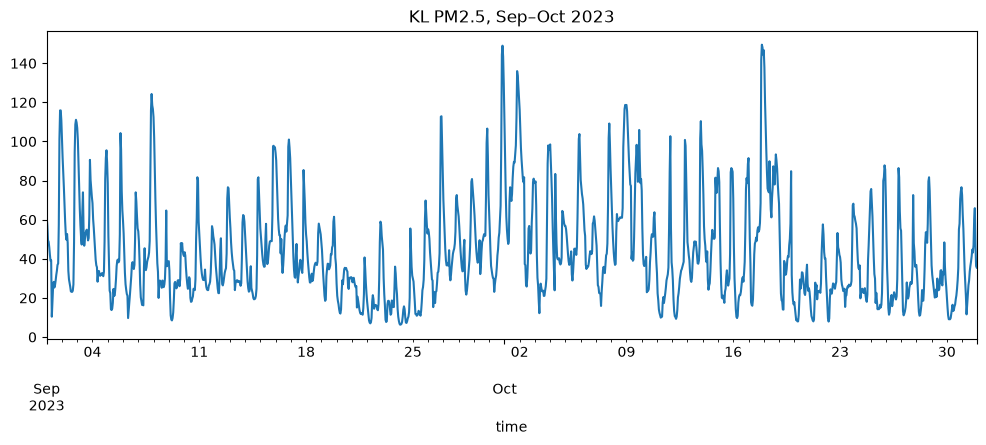

In [12]:
df = pd.read_csv(RAW_DIR / "zones_hourly.csv", parse_dates=["time"])

print(df.shape, df["zone"].nunique())       # expect ~11k rows per zone, 15 zones
print(df.isna().mean())                     # share of missing values per column

kl = df[(df.zone == "Kuala Lumpur") & (df.time >= "2023-09-01")]
kl.set_index("time")["pm25"].plot(figsize=(12, 4), title="KL PM2.5, Sep–Oct 2023")